In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

In [148]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

In [203]:
df.sample()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
347,348,Female,57,Nurse,8.2,9,75,3,Overweight,140/95,68,7000,Sleep Apnea


In [154]:
df.dropna(inplace=True)

In [240]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic Pressure,Diastolic Pressure
count,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000,155.000000
mean,244.761290,46.632258,6.812258,6.870968,60.896774,5.767742,71.787097,6765.806452,134.922581,89.806452
std,91.282997,7.839311,0.773534,1.337325,20.634158,1.946757,5.187381,1893.921881,5.396651,4.868527
min,4.000000,28.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000,115.000000,75.000000
25%,199.500000,43.000000,6.300000,6.000000,45.000000,4.000000,68.000000,6000.000000,130.000000,85.000000
50%,255.000000,45.000000,6.500000,7.000000,45.000000,7.000000,72.000000,6000.000000,135.000000,90.000000
75%,304.500000,51.000000,7.400000,8.000000,75.000000,7.000000,75.000000,7000.000000,140.000000,95.000000
max,374.000000,59.000000,8.300000,9.000000,90.000000,8.000000,86.000000,10000.000000,142.000000,95.000000


In [155]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 155 entries, 3 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                155 non-null    int64  
 1   Gender                   155 non-null    object 
 2   Age                      155 non-null    int64  
 3   Occupation               155 non-null    object 
 4   Sleep Duration           155 non-null    float64
 5   Quality of Sleep         155 non-null    int64  
 6   Physical Activity Level  155 non-null    int64  
 7   Stress Level             155 non-null    int64  
 8   BMI Category             155 non-null    object 
 9   Blood Pressure           155 non-null    object 
 10  Heart Rate               155 non-null    int64  
 11  Daily Steps              155 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 17.0+ KB


In [236]:
def low(x):
    return int(x.split("/")[0])
def high(x):
    return int(x.split("/")[1])
    

In [237]:
df['Systolic Pressure'] = df['Blood Pressure'].apply(low)
df['Diastolic Pressure'] = df['Blood Pressure'].apply(high)

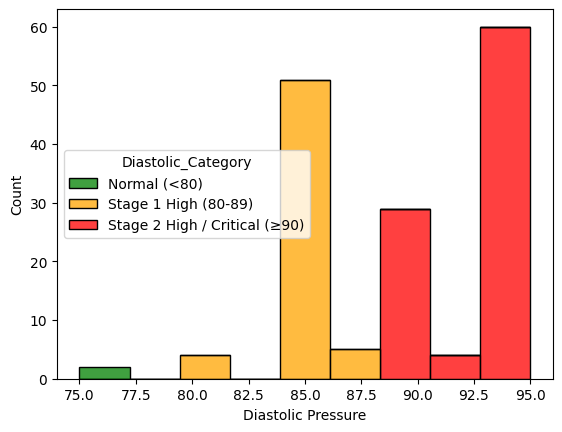

In [238]:
# 1. Define the Diastolic categories based on medical guidelines
bins = [0, 80, 90, np.inf]
labels = ["Normal (<80)", "Stage 1 High (80-89)", "Stage 2 High / Critical (≥90)"]

df["Diastolic_Category"] = pd.cut(
    df["Diastolic Pressure"], bins=bins, labels=labels, right=False
)

# 2. Plot the colored histogram
sns.histplot(
    data=df,
    x="Diastolic Pressure",
    hue="Diastolic_Category",
    multiple="stack",
    palette={"Normal (<80)": "green", "Stage 1 High (80-89)": "orange", "Stage 2 High / Critical (≥90)": "red"},
)

plt.show()

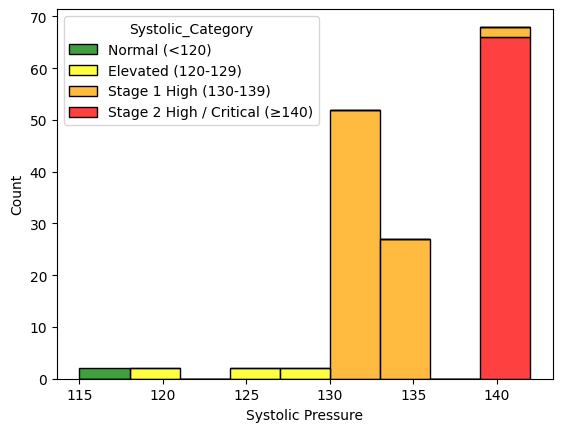

In [239]:
# 1. Define the Systolic categories based on medical guidelines
bins = [0, 120, 130, 140, np.inf]
labels = [
    "Normal (<120)",
    "Elevated (120-129)",
    "Stage 1 High (130-139)",
    "Stage 2 High / Critical (≥140)",
]

df["Systolic_Category"] = pd.cut(
    df["Systolic Pressure"], bins=bins, labels=labels, right=False
)

# 2. Plot the colored histogram
sns.histplot(
    data=df,
    x="Systolic Pressure",
    hue="Systolic_Category",
    multiple="stack",
    palette={
        "Normal (<120)": "green",
        "Elevated (120-129)": "yellow",
        "Stage 1 High (130-139)": "orange",
        "Stage 2 High / Critical (≥140)": "red",
    },
)

plt.show()

<Axes: xlabel='Age', ylabel='Count'>

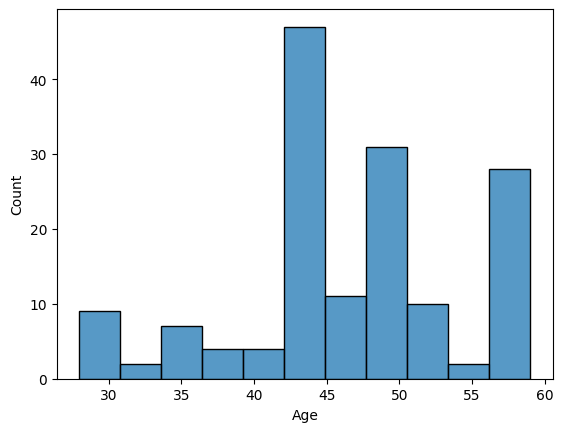

In [241]:
sns.histplot(data=df, x = 'Age')